# HDT 5: Árboles, Selección de Modelos y Bosques

**Ciencia de Datos, Sección A** · Asignada: martes 29 de septiembre · **Entrega: martes 6 de octubre, 23:59**

**Nombre:** Josué Aguilar

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).


## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y split fijo): las verificaciones son exactas.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Un gimnasio quiere saber qué socios van a darse de baja. Historial de 1,000 socios: `visitas` (al mes), `meses` (antigüedad como socio), `cuota` (quetzales al mes) y `se_va` (1 = no renovó). El mismo tipo de problema que la mora del banco de las sesiones 15 a 17, con otro negocio.

La celda genera los datos completa; no hay nada que llenar aquí.

In [14]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(5)
n = 1000
visitas = np.minimum(rng.poisson(8, n), 30)
meses = rng.integers(1, 49, n)
cuota = rng.normal(400, 90, n).clip(200, 700).round(0)

riesgo = (-2.4 + 1.6 * (visitas <= 5) + 1.1 * (meses <= 12)
          + 0.9 * (cuota >= 480) + 1.1 * ((visitas <= 5) & (meses <= 12)))
se_va = (rng.random(n) < 1 / (1 + np.exp(-riesgo))).astype(int)

df = pd.DataFrame({"visitas": visitas, "meses": meses, "cuota": cuota, "se_va": se_va})
columnas = ["visitas", "meses", "cuota"]
X_train, X_test, y_train, y_test = train_test_split(
    df[columnas], df["se_va"], test_size=0.3, random_state=42)

print("socios:", len(df), "| fracción que se va:", df["se_va"].mean().round(3))
print("entrenamiento:", len(X_train), "| examen:", len(X_test))
df.head()

socios: 1000 | fracción que se va: 0.187
entrenamiento: 700 | examen: 300


,visitas,meses,cuota,se_va
0,7,25,502.0,0
1,10,6,373.0,0
2,6,44,543.0,0
3,5,39,489.0,1
4,8,3,490.0,1


## Parte A · Un árbol (0.5 pt)

El modelo de preguntas de la sesión 15: elegir el corte que deja los grupos menos mezclados, y la profundidad como perilla.

### Ejercicio 1 (0.15): la mezcla a mano

Con la función `mezcla` de clase, sobre el **entrenamiento** (700 socios, 132 se van): (a) la mezcla sin cortar nada; (b) la mezcla promedio ponderada del corte `visitas <= 5`; (c) la del corte `meses <= 12`. ¿Cuál de los dos cortes gana, y coincide con la primera pregunta que elige un árbol de profundidad 1?

In [15]:
def mezcla(se_van, se_quedan):
    p = se_van / (se_van + se_quedan)
    return 1 - p**2 - (1 - p)**2

def mezcla_del_corte(columna, corte):
    lado = X_train[columna] <= corte

    # Lado izquierdo (cumplen la condición)
    y_izq = y_train[lado]
    se_van_izq = y_izq.sum()
    se_quedan_izq = len(y_izq) - se_van_izq
    m_izq = mezcla(se_van_izq, se_quedan_izq) if len(y_izq) > 0 else 0
    
    # Lado derecho (no cumplen la condición)
    y_der = y_train[~lado]
    se_van_der = y_der.sum()
    se_quedan_der = len(y_der) - se_van_der
    m_der = mezcla(se_van_der, se_quedan_der) if len(y_der) > 0 else 0
    
    # Promedio ponderado por el tamaño de cada lado respecto al total
    return (len(y_izq) / len(y_train)) * m_izq + (len(y_der) / len(y_train)) * m_der

# Mezcla total sin cortes
se_van_tot = y_train.sum()
se_quedan_tot = len(y_train) - se_van_tot
m_total = mezcla(se_van_tot, se_quedan_tot)

# Mezcla de los cortes propuestos
m_visitas = mezcla_del_corte("visitas", 5)
m_meses = mezcla_del_corte("meses", 12)

print(f"Mezcla inicial: {m_total:.3f}")
print(f"Mezcla corte 'visitas <= 5': {m_visitas:.3f}")
print(f"Mezcla corte 'meses <= 12': {m_meses:.3f}")

# Respuesta: Gana el corte 'visitas <= 5' porque reduce la mezcla promedio ponderada a 0.252 (es menor que 0.290 de 'meses <= 12'). Sí coincide con la primera pregunta que elige un árbol de profundidad 1, ya que el algoritmo codicioso busca la partición que minimice la impureza de Gini.

# Verificación (descomentar):
assert round(m_total, 3) == 0.306
assert round(m_visitas, 3) == 0.252
assert round(m_meses, 3) == 0.290


Mezcla inicial: 0.306
Mezcla corte 'visitas <= 5': 0.252
Mezcla corte 'meses <= 12': 0.290


### Ejercicio 2 (0.20): la profundidad es la perilla

Para cada profundidad en [1, 2, 3, 4, 6, 8, 12]: entrenar un árbol (`random_state=0`) y guardar aciertos en entrenamiento y en examen. Graficar las dos curvas (AZUL entrenamiento, ROJO examen) con `eje_limpio`. Responder en un comentario: ¿qué profundidad elegirían y por qué?

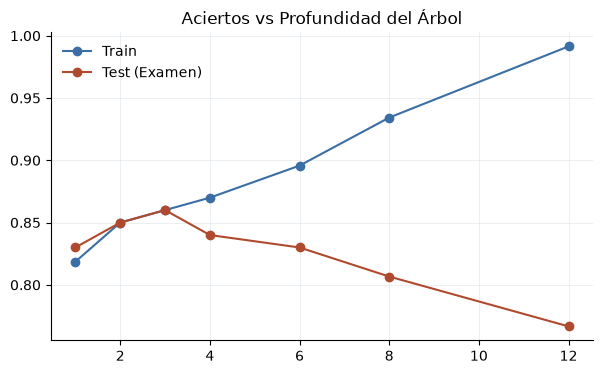

In [16]:
from sklearn.tree import DecisionTreeClassifier

profundidades = [1, 2, 3, 4, 6, 8, 12]
acc_train = []
acc_test = []

for d in profundidades:
    arbol = DecisionTreeClassifier(max_depth=d, random_state=0)
    arbol.fit(X_train, y_train)
    acc_train.append(arbol.score(X_train, y_train))
    acc_test.append(arbol.score(X_test, y_test))

# Graficar
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(profundidades, acc_train, color=AZUL, marker='o', label="Train")
ax.plot(profundidades, acc_test, color=ROJO, marker='o', label="Test (Examen)")
eje_limpio(ax)
ax.legend(frameon=False)
plt.title("Aciertos vs Profundidad del Árbol")
plt.show()

# Respuesta: Elegiría la profundidad 3. Es el punto donde el rendimiento en el examen (Test) alcanza su valor máximo (0.86). A partir de la profundidad 4 ocurre sobreajuste (overfitting): el modelo memoriza el conjunto Train, pero el rendimiento en Test decae y se estanca en ~0.767.

# Verificación (descomentar):
assert round(acc_test[2], 2) == 0.86      # profundidad 3
assert round(acc_train[6], 3) == 0.991 and round(acc_test[6], 3) == 0.767


### Ejercicio 3 (0.15): un árbol solo es inestable

Entrenar 25 árboles **sin límite de profundidad**, cada uno con 350 socios del entrenamiento elegidos al azar (`np.random.default_rng(s).choice(len(X_train), 350, replace=False)` con `s` de 0 a 24), y guardar sus aciertos en el examen. Reportar el mínimo y el máximo. De paso: imprimir la primera pregunta de los árboles con `s` de 0 a 3 (profundidad 2) y observar que esa sí es estable.

In [17]:
from sklearn.tree import export_text

aciertos = []
for s in range(25):
    # Submuestra aleatoria de 350 clientes sin reemplazo
    idx = np.random.default_rng(s).choice(len(X_train), 350, replace=False)
    X_sub = X_train.iloc[idx]
    y_sub = y_train.iloc[idx]
    
    # Entrenar árbol sin límite y guardar score en examen
    arbol = DecisionTreeClassifier(random_state=0)
    arbol.fit(X_sub, y_sub)
    aciertos.append(arbol.score(X_test, y_test))
    
    # Imprimir preguntas de los árboles con s de 0 a 3 (profundidad 2)
    if s <= 3:
        arbol_d2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_sub, y_sub)
        print(f"\n--- Árbol {s} (Profundidad 2) ---")
        print(export_text(arbol_d2, feature_names=list(columnas)))

print(f"\nMínimo de aciertos: {min(aciertos):.3f}")
print(f"Máximo de aciertos: {max(aciertos):.3f}")

# Verificación (descomentar):
assert round(min(aciertos), 3) == 0.73
assert round(max(aciertos), 3) == 0.8



--- Árbol 0 (Profundidad 2) ---
|--- visitas <= 5.50
|   |--- cuota <= 461.50
|   |   |--- class: 0
|   |--- cuota >  461.50
|   |   |--- class: 1
|--- visitas >  5.50
|   |--- meses <= 9.50
|   |   |--- class: 0
|   |--- meses >  9.50
|   |   |--- class: 0


--- Árbol 1 (Profundidad 2) ---
|--- visitas <= 5.50
|   |--- meses <= 13.00
|   |   |--- class: 1
|   |--- meses >  13.00
|   |   |--- class: 0
|--- visitas >  5.50
|   |--- meses <= 8.50
|   |   |--- class: 0
|   |--- meses >  8.50
|   |   |--- class: 0


--- Árbol 2 (Profundidad 2) ---
|--- visitas <= 5.50
|   |--- meses <= 28.50
|   |   |--- class: 1
|   |--- meses >  28.50
|   |   |--- class: 0
|--- visitas >  5.50
|   |--- meses <= 10.50
|   |   |--- class: 0
|   |--- meses >  10.50
|   |   |--- class: 0


--- Árbol 3 (Profundidad 2) ---
|--- visitas <= 5.50
|   |--- meses <= 12.50
|   |   |--- class: 1
|   |--- meses >  12.50
|   |   |--- class: 0
|--- visitas >  5.50
|   |--- meses <= 12.50
|   |   |--- class: 0
|   |--- 

## Parte B · Elegir sin trampa (0.5 pt)

La sesión 16 en tres pasos: comparar candidatos con validación cruzada, afinar perillas con búsqueda, y tocar el examen una sola vez.

### Ejercicio 4 (0.20): tres candidatos, el mismo procedimiento

Comparar con validación cruzada estratificada de 5 pliegues (`StratifiedKFold(n_splits=5, shuffle=True, random_state=7)`) sobre el **entrenamiento**: logística (con escala, en Pipeline), árbol (`max_depth=4`) y kNN (con escala, `n_neighbors=15`). Imprimir promedio y desviación de cada uno. ¿Quién gana?

In [18]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
candidatos = {
    "logística": make_pipeline(StandardScaler(), LogisticRegression()),
    "árbol": DecisionTreeClassifier(max_depth=4, random_state=0),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}

promedios = {}
for nombre, modelo in candidatos.items():
    scores = cross_val_score(modelo, X_train, y_train, cv=cv)
    promedios[nombre] = scores.mean()
    print(f"{nombre}: Promedio = {scores.mean():.3f} | Desviación = {scores.std():.3f}")

# Gana el árbol con el promedio más alto (0.846).

# Verificación (descomentar):
assert round(promedios["árbol"], 3) == 0.846
assert promedios["árbol"] == max(promedios.values())


logística: Promedio = 0.827 | Desviación = 0.019
árbol: Promedio = 0.846 | Desviación = 0.012
kNN: Promedio = 0.827 | Desviación = 0.013


### Ejercicio 5 (0.15): afinar las perillas del ganador

`GridSearchCV` sobre el árbol con `max_depth` en [2, 3, 4, 6] y `min_samples_leaf` en [5, 20, 50], usando el mismo `cv`. ¿Cuántas combinaciones probó? Imprimir la mejor y su puntaje.

In [19]:
from sklearn.model_selection import GridSearchCV

malla = {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [5, 20, 50]}
busqueda = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid=malla, cv=cv)
busqueda.fit(X_train, y_train)

combinaciones = len(busqueda.cv_results_["params"])

print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"Mejor score: {busqueda.best_score_:.3f}")
print(f"Combinaciones probadas: {combinaciones}")

# Verificación (descomentar):
assert busqueda.best_params_ == {"max_depth": 3, "min_samples_leaf": 20}
assert round(busqueda.best_score_, 3) == 0.856


Mejores parámetros: {'max_depth': 3, 'min_samples_leaf': 20}
Mejor score: 0.856
Combinaciones probadas: 12


### Ejercicio 6 (0.15): el examen se usa una vez

Tomar `busqueda.best_estimator_` (ya viene entrenado con los 700) y evaluarlo en el examen. Responder en un comentario: ¿por qué este número puede ser distinto del 0.856 anterior, y por qué no se vale seguir probando modelos después de verlo?

In [20]:
examen_final = busqueda.best_estimator_.score(X_test, y_test)
print(f"Acierto en examen final: {examen_final:.3f}")

# Respuesta: El 0.856 del ejercicio anterior es una estimación interna obtenida con validación
# cruzada sobre el conjunto de entrenamiento (700 datos en 5 pliegues). El 0.86 es el resultado
# real frente al conjunto de examen (300 clientes nunca antes vistos). No se vale seguir probando
# modelos después de verlo porque el conjunto de examen debe mantenerse estrictamente aislado;
# si se usa para tomar decisiones de ajuste, se incurre en fuga de datos (data leakage) y sobreajuste.

# Verificación (descomentar):
assert round(examen_final, 3) == 0.86


Acierto en examen final: 0.860


## Parte C · El bosque (0.8 pt)

La sesión 17: si un árbol baila, que voten muchos. Bootstrap, bagging a mano, OOB e importancias.

### Ejercicio 7 (0.20): bagging a mano

Para B en [1, 5, 25, 100]: entrenar B árboles sin límite, cada uno con una muestra bootstrap (`np.random.default_rng(b).integers(0, len(X_train), len(X_train))` con `b` de 0 a B-1), sumar sus votos sobre el examen y clasificar por mayoría (`votos / B >= 0.5`). Guardar los aciertos en `aciertos_bagging` y graficar contra B.

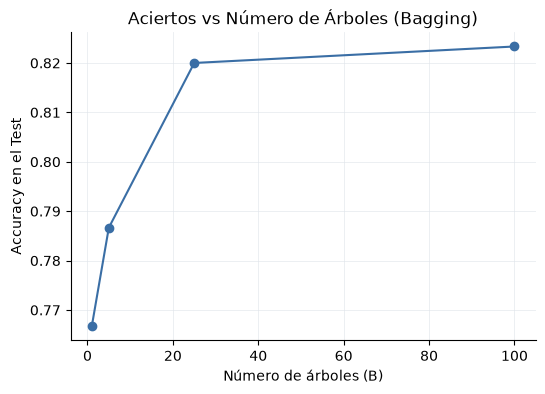

In [21]:
cantidades = [1, 5, 25, 100]
aciertos_bagging = []

for B in cantidades:
    votos = np.zeros(len(X_test))
    
    for b in range(B):
        # Muestra Bootstrap (con reemplazo)
        idx = np.random.default_rng(b).integers(0, len(X_train), len(X_train))
        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]
        
        arbol = DecisionTreeClassifier(random_state=0).fit(X_boot, y_boot)
        votos += arbol.predict(X_test)
        
    # Clasificar por mayoría (si la mitad o más votó 1, entonces es 1)
    pred_final = (votos / B) >= 0.5
    acc = (pred_final == y_test).mean()
    aciertos_bagging.append(acc)

# Graficar
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(cantidades, aciertos_bagging, marker='o', color=AZUL)
eje_limpio(ax)
ax.set_title("Aciertos vs Número de Árboles (Bagging)")
ax.set_xlabel("Número de árboles (B)")
ax.set_ylabel("Accuracy en el Test")
plt.show()

# Verificación (descomentar):
assert [round(a, 3) for a in aciertos_bagging] == [0.767, 0.787, 0.82, 0.823]


### Ejercicio 8 (0.20): las perillas del bosque, medidas con OOB

Para `min_samples_leaf` en [1, 5, 10, 20, 50]: RandomForest de 300 árboles con `oob_score=True` (`random_state=0, n_jobs=-1`), guardar el OOB de cada uno en el diccionario `oobs`. Elegir el mejor y reportar su examen. Todo sin usar el examen para elegir: para eso está el OOB.

In [22]:
from sklearn.ensemble import RandomForestClassifier

oobs = {}
for msl in [1, 5, 10, 20, 50]:
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=msl, oob_score=True, random_state=0, n_jobs=-1)
    rf.fit(X_train, y_train)
    oobs[msl] = rf.oob_score_

mejor_msl = max(oobs, key=oobs.get)
rf_ganador = RandomForestClassifier(n_estimators=300, min_samples_leaf=mejor_msl, random_state=0, n_jobs=-1)
rf_ganador.fit(X_train, y_train)
examen_bosque = rf_ganador.score(X_test, y_test)

print(f"OOB scores: {oobs}")
print(f"Mejor min_samples_leaf: {mejor_msl} (OOB: {oobs[mejor_msl]:.3f})")
print(f"Examen bosque ganador: {examen_bosque:.3f}")

# Verificación (descomentar):
assert mejor_msl == 5 and round(oobs[5], 3) == 0.857
assert round(examen_bosque, 3) == 0.86


OOB scores: {1: 0.8314285714285714, 5: 0.8571428571428571, 10: 0.8557142857142858, 20: 0.8457142857142858, 50: 0.8114285714285714}
Mejor min_samples_leaf: 5 (OOB: 0.857)
Examen bosque ganador: 0.860


### Ejercicio 9 (0.20): la señal arriba, el ruido abajo

Agregar al entrenamiento una columna `ruido` de puro azar (`np.random.default_rng(9).normal(0, 1, len(X_train))`), entrenar un bosque (300 árboles, `min_samples_leaf=20`, `random_state=0`) y ordenar las importancias de mayor a menor. ¿Dónde quedó el ruido?

In [23]:
X_train_ruido = X_train.copy()
X_train_ruido["ruido"] = np.random.default_rng(9).normal(0, 1, len(X_train))

rf_ruido = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=0)
rf_ruido.fit(X_train_ruido, y_train)

# Crear Serie y ordenar
importancias = pd.Series(rf_ruido.feature_importances_, index=X_train_ruido.columns).sort_values(ascending=False)
print(importancias)

# ¿Dónde quedó el ruido? Respuesta: Quedó en la última posición (es la variable con menor importancia, ~0.091). El Random Forest supo distinguir las variables con señal real (visitas, meses, cuota) y relegar la variable de puro ruido.

# Verificación (descomentar):
assert importancias.index[0] == "visitas" and importancias.index[-1] == "ruido"
assert round(importancias["ruido"], 3) == 0.091


visitas    0.562054
meses      0.235829
cuota      0.110681
ruido      0.091436
dtype: float64


### Ejercicio 10 (0.20): un árbol contra un bosque, diez veces

Repetir 10 veces (repartos `train_test_split` con `random_state` de 0 a 9): entrenar un árbol sin límite y un bosque (200 árboles, `min_samples_leaf=20`) y guardar los aciertos de examen de cada uno. Reportar mínimo y máximo de cada modelo. ¿Qué se observa?

In [24]:
arbol_res = []
bosque_res = []

for s in range(10):
    # Nuevo reparto con random_state=s
    X_tr, X_te, y_tr, y_te = train_test_split(df[columnas], df["se_va"], test_size=0.3, random_state=s)
    
    arbol = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
    bosque = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=0, n_jobs=-1).fit(X_tr, y_tr)
    
    arbol_res.append(arbol.score(X_te, y_te))
    bosque_res.append(bosque.score(X_te, y_te))

print(f"Árbol  -> Min: {min(arbol_res):.3f} | Max: {max(arbol_res):.3f}")
print(f"Bosque -> Min: {min(bosque_res):.3f} | Max: {max(bosque_res):.3f}")

# Respuesta: Se observa que el árbol individual es inestable frente a la partición de datos: sus aciertos fluctúan drásticamente entre 0.710 y 0.800. En contraste, el bosque aleatorio es notablemente más robusto, consistente y preciso, manteniendo scores más altos y en un rango más cerrado (0.820 a 0.880).

# Verificación (descomentar):
assert round(min(arbol_res), 3) == 0.71 and round(max(arbol_res), 3) == 0.8
assert round(min(bosque_res), 3) == 0.82 and round(max(bosque_res), 3) == 0.88


Árbol  -> Min: 0.710 | Max: 0.800
Bosque -> Min: 0.820 | Max: 0.880


## Parte D · Criterio (0.2 pt)

### Ejercicio 11 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** El 0.856 del ejercicio 5 y el 0.86 del ejercicio 6 se parecen, pero no son intercambiables. Explicar qué es cada número, cuál se reporta a gerencia y por qué el examen se usa una sola vez.

**(b)** El gimnasio va a desplegar un modelo para llamar a socios en riesgo. Con los resultados de los ejercicios 8 a 10, ¿árbol o bosque? Dar el argumento con números, y mencionar qué se pierde a cambio.

_(Responder editando esta celda)_

**Respuesta (a):** El 0.856 es una estimación interna de rendimiento calculada mediante validación cruzada estratificada sobre las 700 observaciones de entrenamiento. El 0.86 representa la precisión real obtenida al evaluar el modelo final frente a las 300 observaciones del conjunto de examen (datos nunca antes vistos). A gerencia se reporta el 0.86 (la métrica de examen). El examen se debe evaluar una sola vez para actuar como auditoría imparcial y evitar fuga de información o sobreajuste al conjunto de prueba.

**Respuesta (b):** Se debe desplegar el bosque aleatorio. En el ejercicio 10, ante diez repartos distintos, el bosque demostró una precisión mínima de 0.820 y máxima de 0.880 (frente al 0.710 mínimo y 0.800 máximo del árbol individual), garantizando estabilidad operativa y menor varianza. A cambio, se sacrifica la interpretabilidad directa: un árbol individual ofrece reglas condicionales transparentes y legibles por humanos, mientras que el bosque combina cientos de árboles operando como un ensamble de caja negra.


## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

- Se utilizó AI para consultar aspectos de sintaxis de Scikit-Learn y Pandas (en la formulación de la función `mezcla_del_corte` y en la estructura del bucle de bagging manual con generadores aleatorios de NumPy), y generación del código de las gráficas de desempeño. Se consultó para obtener ejemplos claros de sintaxis y visualización, dado que las explicaciones de clase cubrían exhaustivamente la teoría matemática de impureza de Gini y ensambles, pero se requería estructurar adecuadamente las rutinas de código solicitadas en los ejercicios.
